## EDA Data Valorant VCT 2023 - 2026
Melakukan EDA terhadap dataset vct

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path(".")                      # folder yang berisi vct_2021 ... vct_2026
YEARS = [2023, 2024, 2025, 2026]      # data utama untuk training
KEY = ['Tournament', 'Stage', 'Match Type', 'Match Name', 'Map', 'Team']   # 1 komposisi = 1 tim di 1 map

def read(year, sub, name):
    path = BASE / f"vct_{year}" / sub / name
    return pd.read_csv(path, keep_default_na=False, na_values=[''], low_memory=False)

## Profiling datanya secara dasar
Membaca data dari tahun 2023 - 2026, degan menambah kolom Tahun, lalu gabungin jadi 1 tabel yang namanya `overview`.

In [2]:
frames = []
for y in YEARS:
    o = read(y, "matches", "overview.csv")
    o['Tahun'] = y
    frames.append(o)
overview = pd.concat(frames, ignore_index=True)

print("bentuk data:", overview.shape)
overview.head()

bentuk data: (171162, 22)


,Tournament,Stage,Match Type,Match Name,Map,Player,Team,Agents,Rating,Average Combat Score,...,Assists,Kills - Deaths (KD),"Kill, Assist, Trade, Survive %",Average Damage Per Round,Headshot %,First Kills,First Deaths,Kills - Deaths (FKD),Side,Tahun
0,Valorant Champions 2023,Group Stage,Opening (D),Team Liquid vs Natus Vincere,Fracture,nAts,Team Liquid,viper,1.20,242.0,...,3.0,5.0,67%,144.0,33%,3.0,3.0,0.0,both,2023
1,Valorant Champions 2023,Group Stage,Opening (D),Team Liquid vs Natus Vincere,Fracture,nAts,Team Liquid,viper,1.40,268.0,...,1.0,5.0,75%,162.0,46%,1.0,1.0,0.0,attack,2023
2,Valorant Champions 2023,Group Stage,Opening (D),Team Liquid vs Natus Vincere,Fracture,nAts,Team Liquid,viper,1.00,217.0,...,2.0,0.0,58%,125.0,21%,2.0,2.0,0.0,defend,2023
3,Valorant Champions 2023,Group Stage,Opening (D),Team Liquid vs Natus Vincere,Fracture,Sayf,Team Liquid,breach,0.96,170.0,...,10.0,-2.0,71%,112.0,23%,0.0,1.0,-1.0,both,2023
4,Valorant Champions 2023,Group Stage,Opening (D),Team Liquid vs Natus Vincere,Fracture,Sayf,Team Liquid,breach,0.46,81.0,...,6.0,-8.0,58%,50.0,20%,0.0,0.0,0.0,attack,2023


Melihat struktur tabelnya

In [3]:
overview.info()

<class 'pandas.DataFrame'>
RangeIndex: 171162 entries, 0 to 171161
Data columns (total 22 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Tournament                      171162 non-null  str    
 1   Stage                           171162 non-null  str    
 2   Match Type                      171162 non-null  str    
 3   Match Name                      171162 non-null  str    
 4   Map                             171162 non-null  str    
 5   Player                          171162 non-null  str    
 6   Team                            171162 non-null  str    
 7   Agents                          171162 non-null  str    
 8   Rating                          151932 non-null  float64
 9   Average Combat Score            158203 non-null  float64
 10  Kills                           158532 non-null  float64
 11  Deaths                          158532 non-null  float64
 12  Assists                    

Melihat kolom data yang memiliki nilai kosong paling banyak

In [4]:
# 10 kolom dengan nilai kosong terbanyak
overview.isna().sum().sort_values(ascending=False).head(10)

Rating                            19230
Kill, Assist, Trade, Survive %    19064
Average Damage Per Round          17153
Kills - Deaths (FKD)              17017
First Deaths                      17017
First Kills                       17001
Headshot %                        16995
Average Combat Score              12959
Kills - Deaths (KD)               12648
Kills                             12630
dtype: int64

## Membuat tabel komposisi
Dari tabel yang `overview.csv` kita ambil baris side === 'both' dan buang baris ringkasan all maps. Jadinya 1 komposisi = 1 tim pada 1 map, dan valid jika berisi 5 pemain.


In [5]:
pemain = overview[(overview['Side'] == 'both') & (overview['Map'] != 'All Maps')].copy()
pemain['Agents'] = pemain['Agents'].astype(str)

comp = (pemain.groupby(KEY + ['Tahun'])
        .agg(jumlah_pemain=('Player', 'size'), agents=('Agents', list))
        .reset_index())

print("semua komposisi:", len(comp))
print(comp['jumlah_pemain'].value_counts())

n_tidak_valid = int((comp['jumlah_pemain'] != 5).sum())
comp = comp[comp['jumlah_pemain'] == 5].reset_index(drop=True)   # hanya komposisi valid
pick = pemain.merge(comp[KEY], on=KEY)                           # 1 baris = 1 pemain/agent pada komposisi valid

print("komposisi valid:", len(comp), "| baris pemain:", len(pick))
assert len(pick) == len(comp) * 5

semua komposisi: 8192
jumlah_pemain
5    8192
Name: count, dtype: int64
komposisi valid: 8192 | baris pemain: 40960


## Distribusi Kelas
Menghitung yaitu berapa sering tiap agent yang ada itu dipilih

         jumlah  persen
Agents                 
omen       4745    11.6
viper      4031     9.8
sova       3129     7.6
raze       2815     6.9
jett       2651     6.5
killjoy    2533     6.2
cypher     2265     5.5
fade       2099     5.1
neon       1871     4.6
skye       1677     4.1


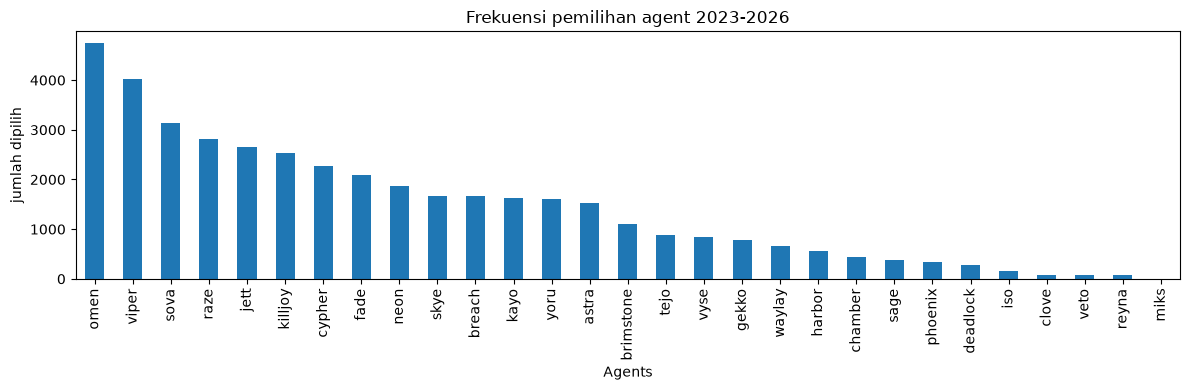

jumlah agent: 29
rasio agent terbanyak : tersedikit = 2372.5


In [6]:
dist = pick['Agents'].value_counts()
tabel = pd.DataFrame({'jumlah': dist, 'persen': (dist / dist.sum() * 100).round(1)})
print(tabel.head(10))

dist.plot(kind='bar', figsize=(12, 4), title='Frekuensi pemilihan agent 2023-2026')
plt.ylabel('jumlah dipilih'); plt.tight_layout(); plt.show()

print("jumlah agent:", len(dist))
print("rasio agent terbanyak : tersedikit =", round(dist.max() / dist.min(), 1))

## Distribusi map
Menghitung berapa kali tiap map dimainkan, dengan menghilangkan duplikat jika satu map dimainlan oleh dua tim.

Map
Lotus       672
Split       491
Haven       487
Bind        423
Ascent      420
Icebox      320
Pearl       317
Sunset      267
Fracture    238
Breeze      199
Abyss       144
Corrode     118
Name: count, dtype: int64


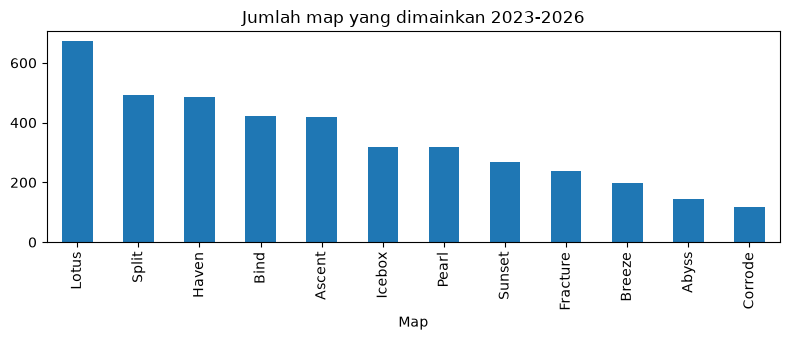

In [7]:
game = comp.drop_duplicates(['Tournament', 'Stage', 'Match Type', 'Match Name', 'Map'])   # 1 baris = 1 map yang dimainkan
map_count = game['Map'].value_counts()
print(map_count)

map_count.plot(kind='bar', figsize=(8, 3.5), title='Jumlah map yang dimainkan 2023-2026')
plt.tight_layout(); plt.show()

## Melihat Agent pick rate di setiap mapnya

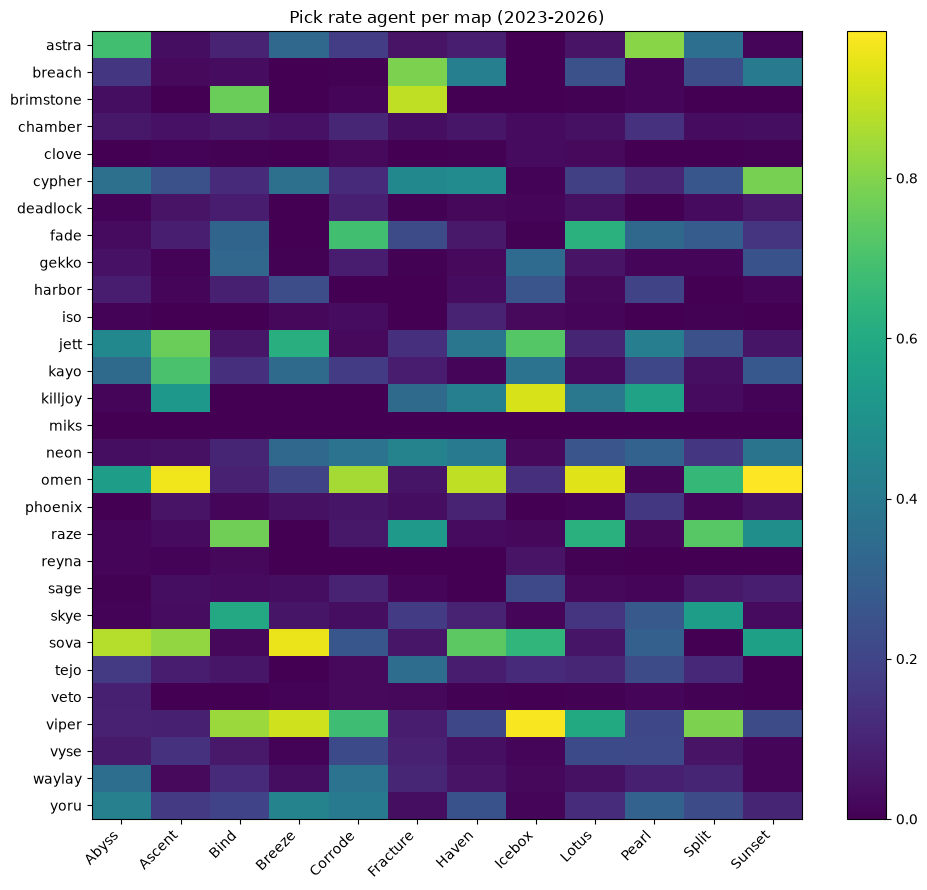

In [8]:
per_map = pick.groupby(['Map', 'Agents']).size().rename('jumlah').reset_index()
total_map = comp.groupby('Map').size().rename('total_komposisi')
per_map = per_map.merge(total_map, on='Map')
per_map['pick_rate'] = per_map['jumlah'] / per_map['total_komposisi']

pr = per_map.pivot(index='Agents', columns='Map', values='pick_rate').fillna(0)

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(pr.values, aspect='auto')
ax.set_xticks(range(len(pr.columns))); ax.set_xticklabels(pr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(pr.index))); ax.set_yticklabels(pr.index)
ax.set_title('Pick rate agent per map (2023-2026)')
fig.colorbar(im); plt.tight_layout(); plt.show()

## Melihat agent win rate
Dihitung dari jumlah mmenang & kalah per agent per map yang dijumlahkan.

In [9]:
tpa = pd.concat([read(y, "agents", "teams_picked_agents.csv") for y in YEARS], ignore_index=True)
print("baris sebelum filter:", len(tpa), "| total Maps Played:", tpa['Total Maps Played'].sum())

tpa = tpa[(tpa['Stage'] != 'All Stages') & (tpa['Match Type'] != 'All Match Types') & (tpa['Map'] != 'All Maps')]
print("baris sesudah filter:", len(tpa), "| total Maps Played:", tpa['Total Maps Played'].sum())
print("pembanding: jumlah baris pemain dari overview =", len(pick))   # harus mendekati

wr = tpa.groupby(['Map', 'Agent'])[['Total Wins By Map', 'Total Loss By Map']].sum()
wr['dimainkan'] = wr.sum(axis=1)
wr['win_rate'] = wr['Total Wins By Map'] / wr['dimainkan']
wr = wr.reset_index()

MIN_MATCH = 5      # batas minimum sampel; boleh diubah
print("kombinasi agent-map:", len(wr), "| yang dimainkan >=", MIN_MATCH, "kali:", (wr['dimainkan'] >= MIN_MATCH).sum())
wr[wr['dimainkan'] >= MIN_MATCH].sort_values('win_rate', ascending=False).head(10)

baris sebelum filter: 57642 | total Maps Played: 85741
baris sesudah filter: 39434 | total Maps Played: 40218
pembanding: jumlah baris pemain dari overview = 40960
kombinasi agent-map: 316 | yang dimainkan >= 5 kali: 271


,Map,Agent,Total Wins By Map,Total Loss By Map,dimainkan,win_rate
144,Fracture,phoenix,9,1,10,0.900000
286,Split,veto,4,1,5,0.800000
204,Icebox,vyse,6,2,8,0.750000
108,Corrode,chamber,16,7,23,0.695652
252,Pearl,raze,9,4,13,0.692308
309,Sunset,sage,31,14,45,0.688889
40,Ascent,neon,22,10,32,0.687500
279,Split,phoenix,4,2,6,0.666667
69,Bind,phoenix,8,4,12,0.666667
29,Ascent,chamber,23,12,35,0.657143


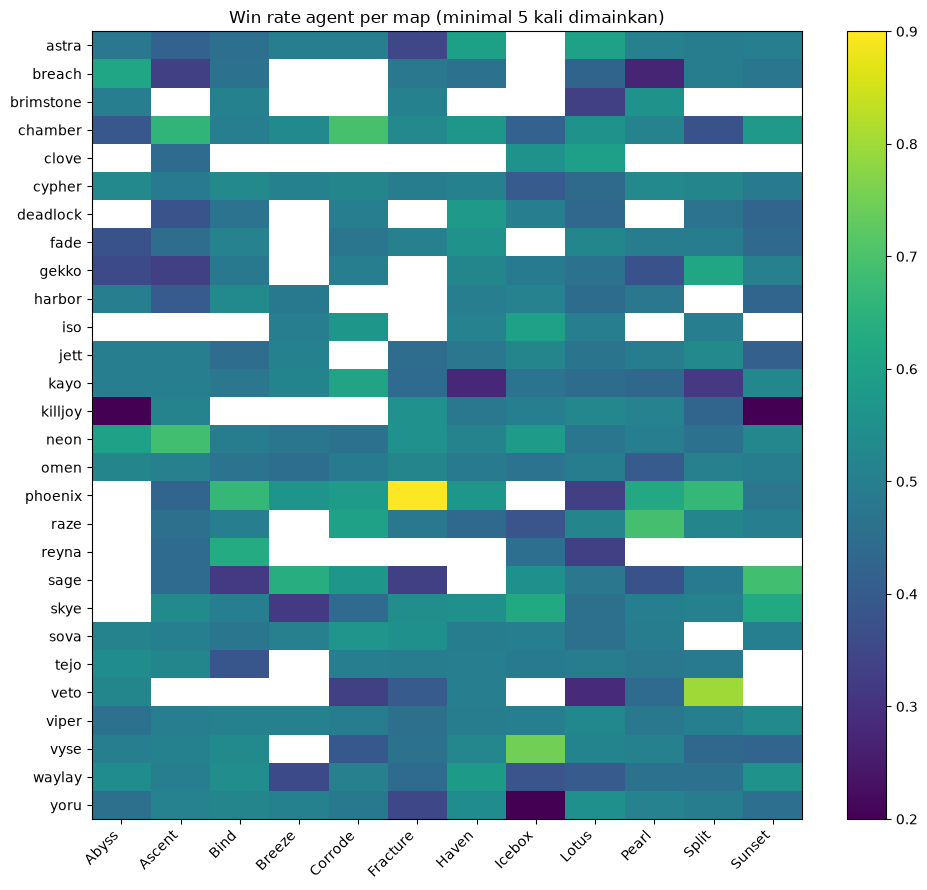

In [10]:
wr_ok = wr[wr['dimainkan'] >= MIN_MATCH]
wr_pivot = wr_ok.pivot(index='Agent', columns='Map', values='win_rate')

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(wr_pivot.values, aspect='auto')
ax.set_xticks(range(len(wr_pivot.columns))); ax.set_xticklabels(wr_pivot.columns, rotation=45, ha='right')
ax.set_yticks(range(len(wr_pivot.index))); ax.set_yticklabels(wr_pivot.index)
ax.set_title(f'Win rate agent per map (minimal {MIN_MATCH} kali dimainkan)')
fig.colorbar(im); plt.tight_layout(); plt.show()

## Mendefinisikan Role Agent
Memberi label role untuk agent - agent yang ada, karena di dataset belum tercantum role untuk tiap agent nya.

In [11]:
ROLE = {
    # Duelist
    'jett': 'Duelist', 'phoenix': 'Duelist', 'reyna': 'Duelist', 'raze': 'Duelist',
    'yoru': 'Duelist', 'neon': 'Duelist', 'iso': 'Duelist', 'waylay': 'Duelist',
    # Initiator
    'sova': 'Initiator', 'breach': 'Initiator', 'skye': 'Initiator', 'kayo': 'Initiator',
    'fade': 'Initiator', 'gekko': 'Initiator', 'tejo': 'Initiator',
    # Controller
    'brimstone': 'Controller', 'omen': 'Controller', 'viper': 'Controller',
    'astra': 'Controller', 'harbor': 'Controller', 'clove': 'Controller',
    # Sentinel
    'sage': 'Sentinel', 'cypher': 'Sentinel', 'killjoy': 'Sentinel',
    'chamber': 'Sentinel', 'deadlock': 'Sentinel', 'vyse': 'Sentinel',
    # agent baru: isi sendiri setelah dicek
    'miks': 'Controller', 'veto': 'Sentinel',
}

agents_data = sorted(pick['Agents'].unique())
print("agent di data:", len(agents_data))
print("agent yang belum punya peran:", [a for a in agents_data if ROLE.get(a) is None])

agent di data: 29
agent yang belum punya peran: []


In [12]:
pick['Peran'] = pick['Agents'].map(ROLE)

# hanya komposisi yang kelima agent-nya sudah punya peran
lengkap = pick.groupby(KEY)['Peran'].apply(lambda s: s.notna().all())
role_count = pick.groupby(KEY)['Peran'].value_counts().unstack(fill_value=0)
role_count = role_count[lengkap.reindex(role_count.index).fillna(False)]
print("komposisi yang dipakai:", len(role_count), "dari", len(comp))

for p in role_count.columns:
    print(p, "-> persentase komposisi menurut jumlah:", role_count[p].value_counts(normalize=True).sort_index().round(3).to_dict())

print()
print("komposisi dengan minimal 1 Controller:", round((role_count['Controller'] >= 1).mean() * 100, 1), "%")
print("komposisi dengan >= 3 Duelist       :", round((role_count['Duelist'] >= 3).mean() * 100, 1), "%")

komposisi yang dipakai: 8192 dari 8192
Controller -> persentase komposisi menurut jumlah: {1: 0.532, 2: 0.465, 3: 0.003}
Duelist -> persentase komposisi menurut jumlah: {0: 0.017, 1: 0.723, 2: 0.26, 3: 0.0}
Initiator -> persentase komposisi menurut jumlah: {0: 0.002, 1: 0.549, 2: 0.445, 3: 0.004}
Sentinel -> persentase komposisi menurut jumlah: {0: 0.229, 1: 0.709, 2: 0.06, 3: 0.002}

komposisi dengan minimal 1 Controller: 100.0 %
komposisi dengan >= 3 Duelist       : 0.0 %


## Melihat agent Teratas tiap tahunnya

2023 [('killjoy', 64.4), ('jett', 61.6), ('skye', 48.1), ('viper', 47.0), ('omen', 46.0)]
2024 [('omen', 64.7), ('viper', 60.0), ('raze', 48.7), ('sova', 41.7), ('cypher', 40.3)]
2025 [('omen', 64.5), ('viper', 41.3), ('sova', 39.9), ('yoru', 35.3), ('cypher', 31.5)]
2026 [('neon', 54.5), ('omen', 51.3), ('viper', 49.3), ('sova', 38.7), ('fade', 36.3)]


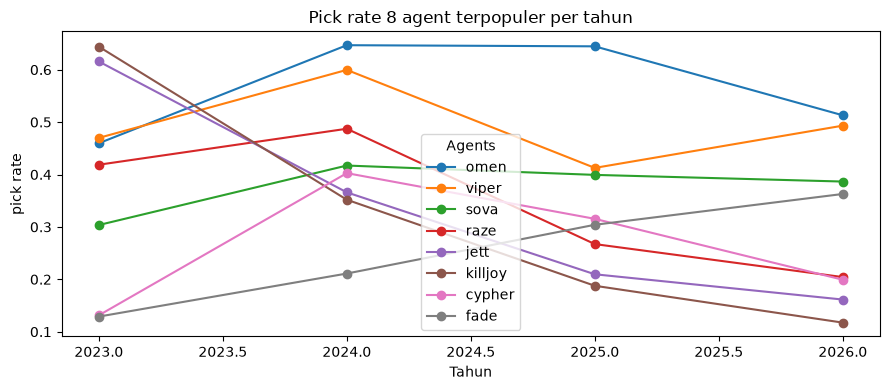

jumlah agent per tahun: {2023: 21, 2024: 24, 2025: 27, 2026: 29}


In [13]:
per_tahun = pick.groupby(['Tahun', 'Agents']).size().rename('jumlah').reset_index()
total_tahun = comp.groupby('Tahun').size().rename('total_komposisi')
per_tahun = per_tahun.merge(total_tahun, on='Tahun')
per_tahun['pick_rate'] = per_tahun['jumlah'] / per_tahun['total_komposisi']

for y in YEARS:
    top = per_tahun[per_tahun['Tahun'] == y].nlargest(5, 'pick_rate')
    print(y, [(a, round(p * 100, 1)) for a, p in zip(top['Agents'], top['pick_rate'])])

tren = per_tahun.pivot(index='Tahun', columns='Agents', values='pick_rate').fillna(0)
tren[dist.head(8).index].plot(figsize=(9, 4), marker='o', title='Pick rate 8 agent terpopuler per tahun')
plt.ylabel('pick rate'); plt.tight_layout(); plt.show()

print("jumlah agent per tahun:", per_tahun.groupby('Tahun')['Agents'].nunique().to_dict())

In [14]:
print("baris duplikat di overview   :", overview.duplicated().sum())
print("pemain bernama 'nan'          :", (overview['Player'] == 'nan').sum())
print("baris tim 'TBD'               :", (overview['Team'] == 'TBD').sum())
print("komposisi tidak berisi 5 pemain:", n_tidak_valid)
print("sel Agents berisi >1 agent    :", pemain['Agents'].str.contains(',').sum())
print("Agents kosong                 :", (pemain['Agents'] == 'nan').sum())

baris duplikat di overview   : 0
pemain bernama 'nan'          : 0
baris tim 'TBD'               : 0
komposisi tidak berisi 5 pemain: 0
sel Agents berisi >1 agent    : 0
Agents kosong                 : 0


In [15]:
# sampel per kombinasi agent-map (untuk menilai apakah win rate bisa dipercaya)
sampel = wr['dimainkan']
print(sampel.describe().round(1))
print(f"kombinasi dengan sampel < {MIN_MATCH}: {(sampel < MIN_MATCH).sum()} dari {len(sampel)}")

count     316.0
mean      127.1
std       190.9
min         1.0
25%        10.0
50%        43.5
75%       158.0
max      1227.0
Name: dimainkan, dtype: float64
kombinasi dengan sampel < 5: 45 dari 316


In [16]:
Path("hasil").mkdir(exist_ok=True)

simpan = comp.copy()
simpan['agents'] = simpan['agents'].apply(lambda l: '|'.join(l))
simpan.to_csv("hasil/komposisi_valid_2023_2026.csv", index=False)
wr.to_csv("hasil/winrate_agent_per_map.csv", index=False)
print("tersimpan:", list(Path("hasil").glob("*.csv")))

tersimpan: [WindowsPath('hasil/hasil_top1.csv'), WindowsPath('hasil/hasil_top3.csv'), WindowsPath('hasil/komposisi_valid_2023_2026.csv'), WindowsPath('hasil/peran_agent.csv'), WindowsPath('hasil/winrate_agent_per_map.csv'), WindowsPath('hasil/winrate_halus_train.csv')]
